Reading sweep:  power_logs/gpt2m-sweep_1729489/
Saving plots:   /bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism/plots/

Loaded 10 configs:
Config                  Nodes   Dur(s)     AvgW   SteadyW    PeakW  Energy(Wh)
----------------------------------------------------------------------------
tp1_pp1_dp8                 2    166.5    639.6     727.1   1472.5       29.58
tp1_pp2_dp4                 2    139.0    664.6     755.4   1376.9       25.66
tp1_pp4_dp2                 2    114.0    678.9     772.0   1305.3       21.50
tp1_pp8_dp1                 2    124.0    661.2     749.7   1111.1       22.77
tp2_pp1_dp4                 2    166.0    664.4     755.3   1065.8       30.64
tp2_pp2_dp2                 2    145.5    668.0     759.3   1024.0       27.00
tp2_pp4_dp1                 2    144.5    662.1     751.0    957.4       26.58
tp4_pp1_dp2                 2    323.5    639.5     686.4    787.1       57.46
tp4_pp2_dp1                 2    313.5    641.4     692.1  

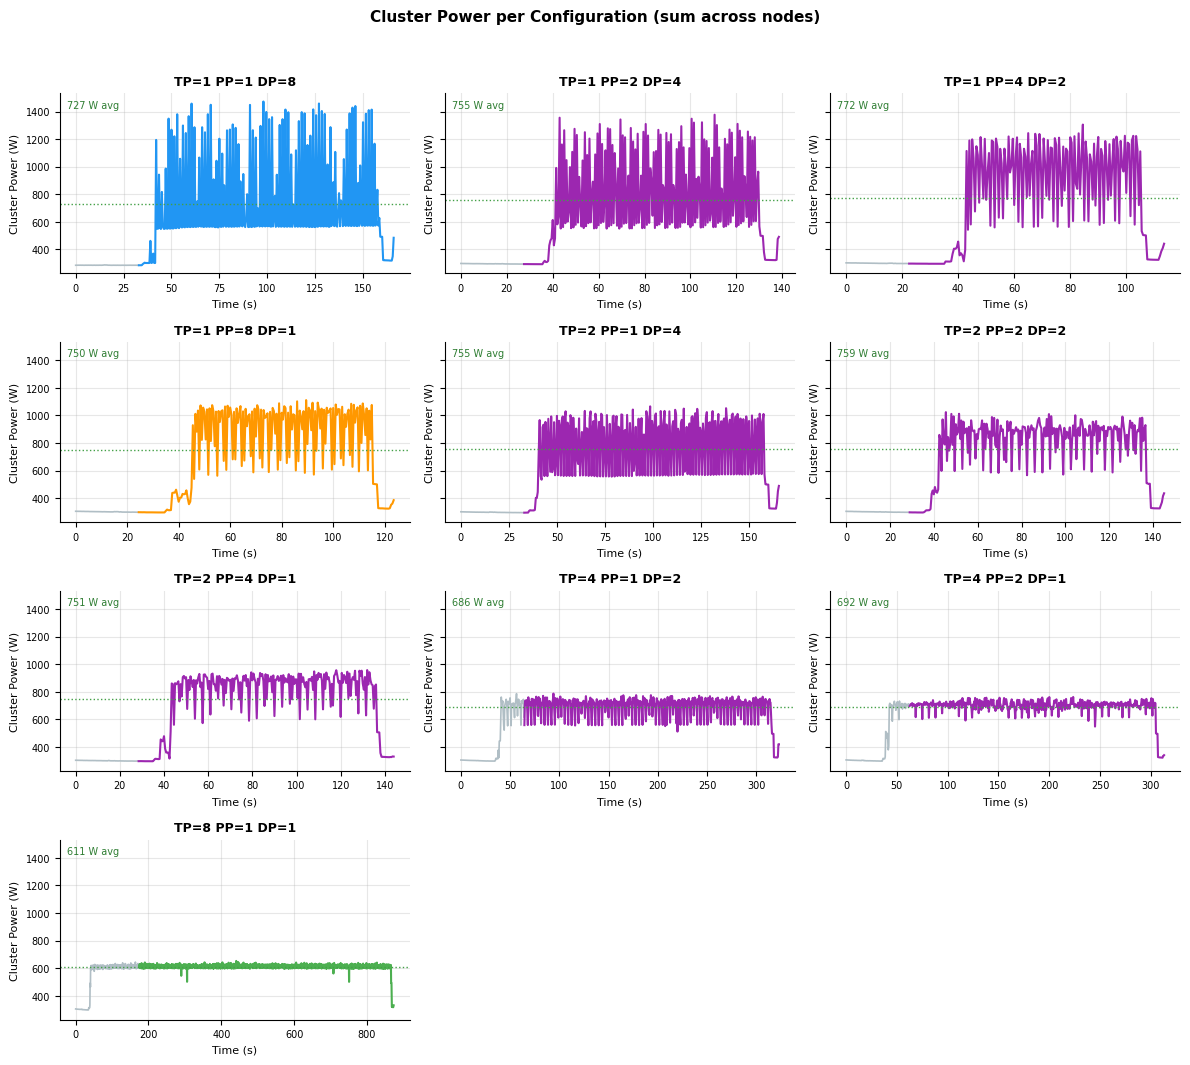

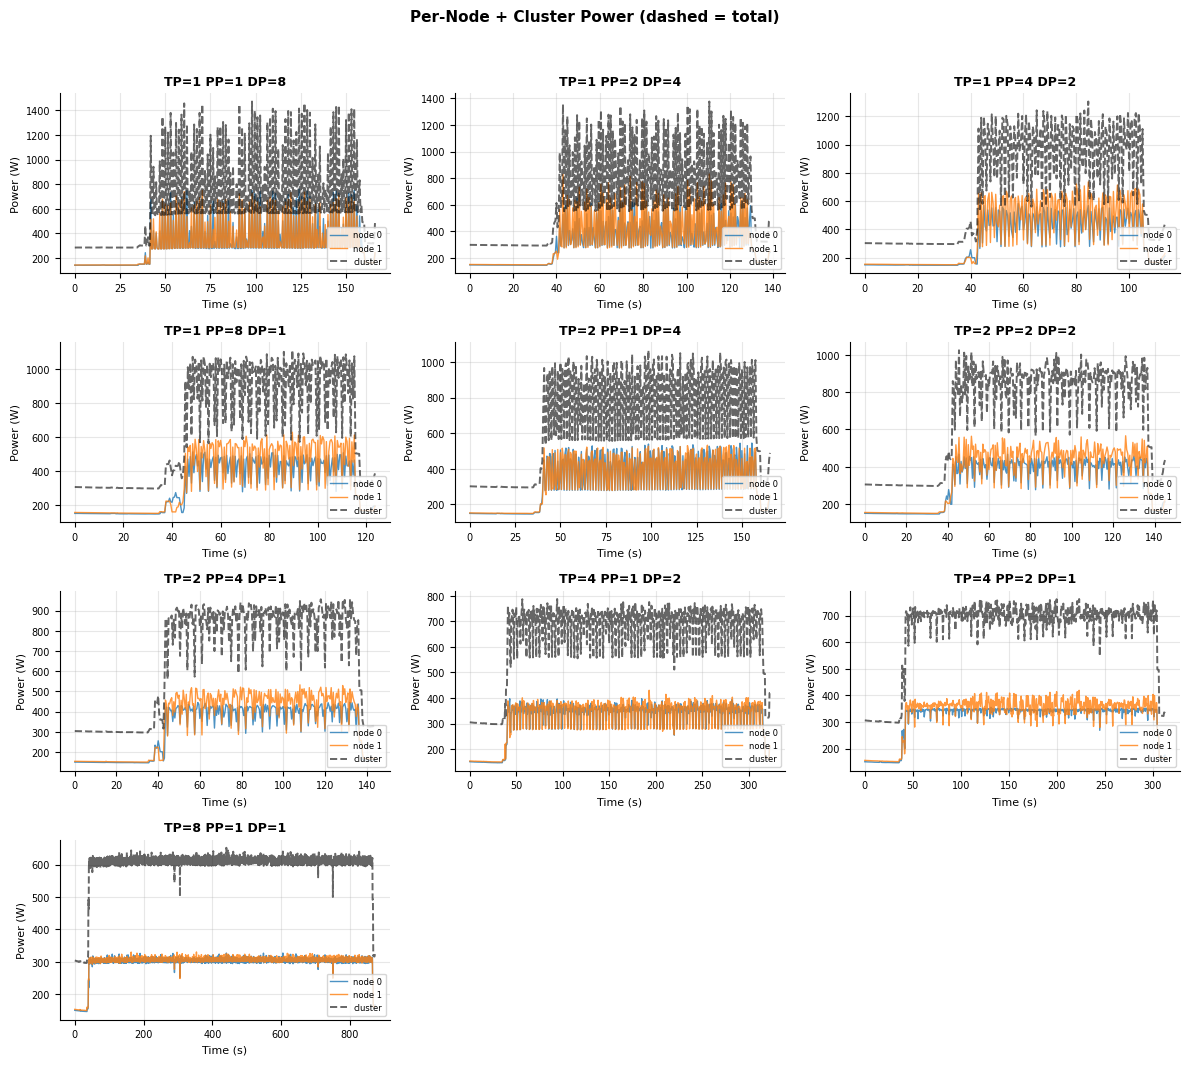

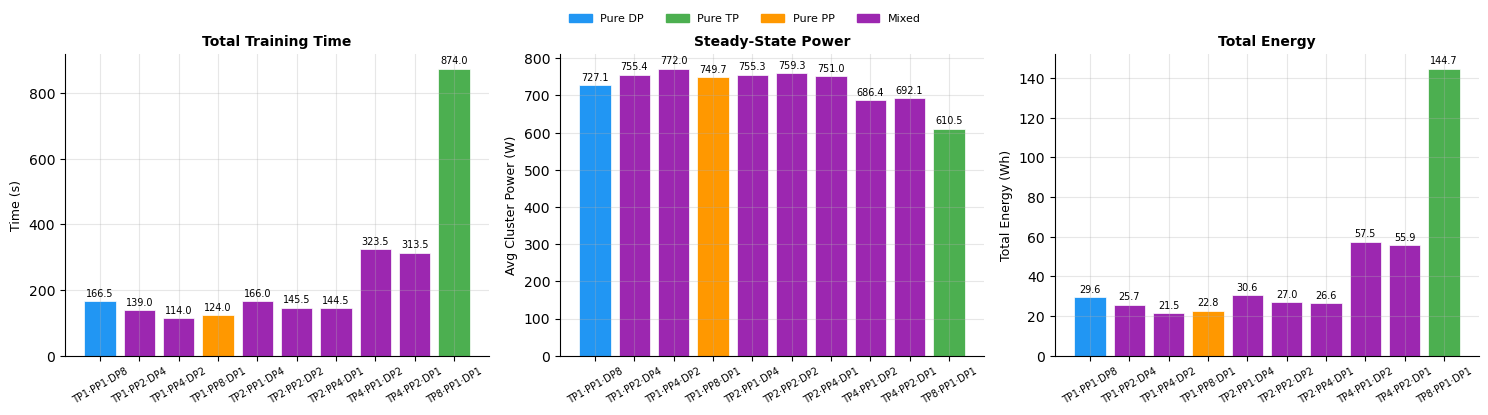


SUMMARY
        Config  Type  Nodes  Time(s)  AvgPower(W)  SteadyPower(W)  PeakPower(W)  Energy(Wh)
TP=1 PP=1 DP=8    dp      2    166.5        639.6           727.1        1472.5       29.58
TP=1 PP=2 DP=4 mixed      2    139.0        664.6           755.4        1376.9       25.66
TP=1 PP=4 DP=2 mixed      2    114.0        678.9           772.0        1305.3       21.50
TP=1 PP=8 DP=1    pp      2    124.0        661.2           749.7        1111.1       22.77
TP=2 PP=1 DP=4 mixed      2    166.0        664.4           755.3        1065.8       30.64
TP=2 PP=2 DP=2 mixed      2    145.5        668.0           759.3        1024.0       27.00
TP=2 PP=4 DP=1 mixed      2    144.5        662.1           751.0         957.4       26.58
TP=4 PP=1 DP=2 mixed      2    323.5        639.5           686.4         787.1       57.46
TP=4 PP=2 DP=1 mixed      2    313.5        641.4           692.1         762.4       55.85
TP=8 PP=1 DP=1    tp      2    874.0        596.2           610.5      

In [1]:
# Multi-node parallel-config power visualization
# ------------------------------------------------
# Reads sweep dirs of the form:
#   power_logs/<sweep>/tpX_ppY_dpZ/rank{0..N}.csv
# Each rankK.csv samples one node's total GPU power at fixed intervals.

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ─── Style ───────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3",     # pure data parallel
    "tp": "#4CAF50",     # tensor parallel only
    "pp": "#FF9800",     # pipeline parallel only
    "mixed": "#9C27B0",  # combinations
}

# ─── Configuration ───────────────────────────────────────────
BASE = os.getcwd()
#SWEEP_DIR = "power_logs/gpt2l-sweep_1729471"   # ← change to your sweep
SWEEP_DIR = "power_logs/gpt2m-sweep_1729489/"   # ← change to your sweep
PLOTS_DIR = os.path.join(BASE, "plots", os.path.basename(SWEEP_DIR))
INTERVAL_SECONDS = 0.5

os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Reading sweep:  {SWEEP_DIR}")
print(f"Saving plots:   {PLOTS_DIR}")

# ─── Helpers ─────────────────────────────────────────────────
CFG_RE = re.compile(r"tp(\d+)_pp(\d+)_dp(\d+)")

def parse_config_name(name):
    m = CFG_RE.match(name)
    if not m:
        return None
    tp, pp, dp = map(int, m.groups())
    return {"tp": tp, "pp": pp, "dp": dp, "name": name}


def classify(cfg):
    """Categorize for coloring."""
    dims = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims >= 2:
        return "mixed"
    if cfg["tp"] > 1: return "tp"
    if cfg["pp"] > 1: return "pp"
    return "dp"


def short_label(cfg):
    return f"TP={cfg['tp']}\nPP={cfg['pp']}\nDP={cfg['dp']}"


def load_config_dir(config_dir):
    """
    Load all rank*.csv files in a sweep config directory and align them
    on a common time axis. Returns a dict with per-rank power series and
    a cluster-wide total (sum across nodes).
    """
    rank_files = sorted(glob.glob(os.path.join(config_dir, "rank*.csv")))
    if not rank_files:
        return None

    rank_series = {}
    for f in rank_files:
        rank = int(re.search(r"rank(\d+)", os.path.basename(f)).group(1))
        df = pd.read_csv(f)
        if "total_power_W" not in df.columns or len(df) < 2:
            continue
        rank_series[rank] = df["total_power_W"].to_numpy()

    if not rank_series:
        return None

    # Align on shortest length (nodes started staggered by ~ms; trim to common)
    n_min = min(len(v) for v in rank_series.values())
    for r in rank_series:
        rank_series[r] = rank_series[r][:n_min]

    cluster_total = np.sum(np.stack(list(rank_series.values())), axis=0)
    time_axis = np.arange(n_min) * INTERVAL_SECONDS

    return {
        "rank_power": rank_series,
        "cluster_power": cluster_total,
        "time": time_axis,
        "n_nodes": len(rank_series),
        "n_samples": n_min,
    }


# ─── Discover and load configs ───────────────────────────────
configs = {}
skipped = []

for d in sorted(os.listdir(SWEEP_DIR)):
    full = os.path.join(SWEEP_DIR, d)
    if not os.path.isdir(full):
        continue
    cfg = parse_config_name(d)
    if cfg is None:
        skipped.append(d)
        continue
    data = load_config_dir(full)
    if data is None:
        skipped.append(d)
        continue
    cfg.update(data)

    # Stats with 20% warmup excluded for steady-state
    p = cfg["cluster_power"]
    warmup = int(len(p) * 0.2)
    steady = p[warmup:] if len(p) > warmup else p
    cfg["avg_power_w"]        = float(p.mean())
    cfg["steady_avg_power_w"] = float(steady.mean())
    cfg["peak_power_w"]       = float(p.max())
    cfg["duration_s"]         = len(p) * INTERVAL_SECONDS
    cfg["energy_wh"]          = float(p.sum()) * INTERVAL_SECONDS / 3600

    configs[d] = cfg

if skipped:
    print(f"Skipped: {', '.join(skipped)}")
if not configs:
    raise RuntimeError(f"No usable configs found under {SWEEP_DIR}")

print(f"\nLoaded {len(configs)} configs:")
print(f"{'Config':<22} {'Nodes':>6} {'Dur(s)':>8} {'AvgW':>8} "
      f"{'SteadyW':>9} {'PeakW':>8} {'Energy(Wh)':>11}")
print("-" * 76)
for name, cfg in configs.items():
    print(f"{name:<22} {cfg['n_nodes']:>6} {cfg['duration_s']:>8.1f} "
          f"{cfg['avg_power_w']:>8.1f} {cfg['steady_avg_power_w']:>9.1f} "
          f"{cfg['peak_power_w']:>8.1f} {cfg['energy_wh']:>11.2f}")

# ─── 1) Cluster-total power trace per config ─────────────────
n = len(configs)
ncols = min(3, n)
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows),
                          sharey=True)
axes = np.atleast_1d(axes).flatten()

for ax, (name, cfg) in zip(axes, configs.items()):
    t = cfg["time"]
    p = cfg["cluster_power"]
    warmup = int(len(p) * 0.2)
    cls = classify(cfg)

    ax.plot(t[:warmup], p[:warmup], color="#B0BEC5", linewidth=1.2)
    ax.plot(t[warmup:], p[warmup:], color=COLORS[cls], linewidth=1.5)
    ax.axhline(cfg["steady_avg_power_w"], color="#43A047",
               linestyle=":", linewidth=1.0)
    ax.set_title(f"TP={cfg['tp']} PP={cfg['pp']} DP={cfg['dp']}",
                 fontsize=9, fontweight="bold")
    ax.set_xlabel("Time (s)", fontsize=8)
    ax.set_ylabel("Cluster Power (W)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.text(0.02, 0.92, f"{cfg['steady_avg_power_w']:.0f} W avg",
            transform=ax.transAxes, fontsize=7, color="#2E7D32")

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("Cluster Power per Configuration (sum across nodes)",
             fontsize=11, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "01_power_per_config.png"),
            dpi=150, bbox_inches="tight")
plt.show()

# ─── 2) Per-node breakdown for each config ───────────────────
# One line per node, plus dotted cluster total
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, (name, cfg) in zip(axes, configs.items()):
    t = cfg["time"]
    for rank, p in sorted(cfg["rank_power"].items()):
        ax.plot(t, p, linewidth=1.0, alpha=0.8, label=f"node {rank}")
    ax.plot(t, cfg["cluster_power"], color="black",
            linewidth=1.4, linestyle="--", alpha=0.6, label="cluster")
    ax.set_title(f"TP={cfg['tp']} PP={cfg['pp']} DP={cfg['dp']}",
                 fontsize=9, fontweight="bold")
    ax.set_xlabel("Time (s)", fontsize=8)
    ax.set_ylabel("Power (W)", fontsize=8)
    ax.tick_params(labelsize=7)
    if cfg["n_nodes"] <= 4:
        ax.legend(fontsize=6, loc="lower right")

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("Per-Node + Cluster Power (dashed = total)",
             fontsize=11, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "02_per_node_breakdown.png"),
            dpi=150, bbox_inches="tight")
plt.show()

# ─── 3) Bar comparison: time, energy, avg power ──────────────
sorted_cfgs = sorted(configs.values(),
                     key=lambda c: (c["tp"], c["pp"], c["dp"]))
labels  = [f"TP{c['tp']}·PP{c['pp']}·DP{c['dp']}" for c in sorted_cfgs]
colors  = [COLORS[classify(c)] for c in sorted_cfgs]
times   = [c["duration_s"]         for c in sorted_cfgs]
avgws   = [c["steady_avg_power_w"] for c in sorted_cfgs]
energy  = [c["energy_wh"]          for c in sorted_cfgs]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, vals, ylabel, title in zip(
    axes,
    [times, avgws, energy],
    ["Time (s)", "Avg Cluster Power (W)", "Total Energy (Wh)"],
    ["Total Training Time", "Steady-State Power", "Total Energy"],
):
    ax.bar(labels, vals, color=colors, edgecolor="white", linewidth=0.5)
    for i, v in enumerate(vals):
        ax.text(i, v + max(vals) * 0.01, f"{v:.1f}",
                ha="center", va="bottom", fontsize=7)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7, rotation=30)

patches = [
    mpatches.Patch(color=COLORS["dp"],    label="Pure DP"),
    mpatches.Patch(color=COLORS["tp"],    label="Pure TP"),
    mpatches.Patch(color=COLORS["pp"],    label="Pure PP"),
    mpatches.Patch(color=COLORS["mixed"], label="Mixed"),
]
fig.legend(handles=patches, ncol=4, fontsize=8,
           loc="upper center", bbox_to_anchor=(0.5, 1.04), frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "03_metrics_overview.png"),
            dpi=150, bbox_inches="tight")
plt.show()

# ─── 4) Summary table ────────────────────────────────────────
rows = []
for c in sorted_cfgs:
    rows.append({
        "Config":      f"TP={c['tp']} PP={c['pp']} DP={c['dp']}",
        "Type":        classify(c),
        "Nodes":       c["n_nodes"],
        "Time(s)":     round(c["duration_s"], 1),
        "AvgPower(W)": round(c["avg_power_w"], 1),
        "SteadyPower(W)": round(c["steady_avg_power_w"], 1),
        "PeakPower(W)": round(c["peak_power_w"], 1),
        "Energy(Wh)":  round(c["energy_wh"], 2),
    })

summary = pd.DataFrame(rows)
print("\n" + "=" * 90)
print("SUMMARY")
print("=" * 90)
print(summary.to_string(index=False))
out_csv = os.path.join(PLOTS_DIR, "summary.csv")
summary.to_csv(out_csv, index=False)
print(f"\nSaved: {out_csv}")